<a href="https://colab.research.google.com/github/HeloiseAlbot/PushQuantum_Hackathon2026_QORO_NetworkDesignProblem/blob/main/Solution001_RefinePartition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# first_solution — network12

Run **Runtime → Run all**. This notebook runs the PCE solution end to end: a first partitioned PCE run, then the same proximity-biased refinement that produced our good solution. The first run supplies the refinement's starting network during this execution.

All code is visible below. The notebook installs its dependencies and downloads the public problem data and the original scoring helper, as in `PARENT_network12.ipynb`. It uses a **local quantum simulator**, so no API key is needed. The graph and final blue number are computed when you run it.

<font color="#f87171"><b>ADDED: standalone solution pipeline. The parent notebook is preserved.</b></font>

In [ ]:
#@title  1 · Install the same Divi version
import os
import sys
import subprocess
from importlib.metadata import version

# Limit native thread pools before importing the simulator.
for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[name] = "1"
os.environ["PYTHON_CPU_COUNT"] = "2"

# Install the extras too, even if the core Divi package was already present.
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                       "qoro-divi[qubo-decompose,jupyter]==0.16.2"])
print("qoro-divi", version("qoro-divi"))


qoro-divi 0.16.2


In [ ]:
#@title 2 · Parameters of the existing PCE solution
N_NODES = 12
BENCHMARK = 276474       # Published comparison value; never used to construct a solution.
PARTITION_LIMIT = 12    # Link variables per quantum partition, not network nodes.
LAYERS = 2
PENALTY_WEIGHT = 1.0
SOFT_ALPHA = 2.0
SHOTS = 2048
POPULATION = 20
ITERATIONS = 5
CANDIDATES_PER_PARTITION = 8
BASE_SEED, REFINE_SEED = 300, 230
BASE_BEAM, REFINE_BEAM = 20, 30
PROXIMITY_WEIGHT = 2.0


In [ ]:
#@title 3 · Imports and the public network data
import hashlib
import importlib
import json
import math
import time
import urllib.request
from pathlib import Path
from collections import Counter

import hybrid
from hybrid import traits
from hybrid.core import Runnable
from hybrid.exceptions import EndOfStream
from hybrid.utils import bqm_induced_by
import numpy as np
from divi.backends import MaestroSimulator, MaestroConfig
from divi.qprog.algorithms import DenseEncoding, PolyEncoding, SoftObjective
from divi.qprog.ensembles import PartitioningProgramEnsemble, BeamSearchStrategy, BatchConfig
from divi.qprog.optimizers import MonteCarloOptimizer
from divi.qprog.problems import BinaryOptimizationProblem, CommunityDecomposer, QUBOPartitioningConfig
from IPython.display import HTML, display

# Same public scoring helper as the parent notebook, pinned to its source revision.
HELPER_URL = "https://raw.githubusercontent.com/QoroQuantum/pushquantum-hackathon-2026/9707be45bb5070cd4f80134fdc9f797acf94b661/qoblib_tools.py"
helper_bytes = urllib.request.urlopen(HELPER_URL, timeout=60).read()
assert hashlib.sha256(helper_bytes).hexdigest() == "8b7a9b6b128818946d99af8311f8df9d0f2d49be9c20beeb42c4514c8987c7b1"
_ = Path("qoblib_tools.py").write_bytes(helper_bytes)
import qoblib_tools as qt
qt = importlib.reload(qt)

demand = qt.load_network_demand(N_NODES)
assert N_NODES == 12 and demand.shape == (12, 12)
assert hashlib.sha256(json.dumps(demand.tolist(), separators=(",", ":")).encode()).hexdigest() == "0b3f54acef690b4d7036d9b4fb0361144c9f8493157fd2c36e09a062d9ee243c"
print(f"{N_NODES} nodes; {N_NODES*(N_NODES-1)} possible directed links.")


12 nodes; 132 possible directed links.


### 1 · Build the topology QUBO

Each binary variable selects one possible link. The starter QUBO rewards direct traffic and penalizes violations of the two-incoming/two-outgoing rule. The routing LP measures the actual congestion.

For refinement, the proximity term favors links in the network just produced by the first PCE run. It shapes the new quantum cost function.

In [ ]:
#@title 4 · The QUBO and its proximity term
from divi.qprog.problems import (
    BinaryOptimizationProblem,
    CommunityDecomposer,
    LinearConstraint,
    QUBOPartitioningConfig,
)

surrogate, degree_penalty, arcs = qt.build_network_qubo(demand)
# degree_penalty is putting a penalty for a wrong number of arcs.
# constraints is imposing it strictly. But constraints can not be used with a decomposer.
constraints = []
for node in range(N_NODES):
    constraints.append(LinearConstraint({v: 1 for v, (i, j) in enumerate(arcs) if i == node}, "==", 2))  # out
    constraints.append(LinearConstraint({v: 1 for v, (i, j) in enumerate(arcs) if j == node}, "==", 2))  # in
# net_problem = BinaryOptimizationProblem(surrogate, constraints=constraints, penalty_weight=2.0)
# print(f"{len(arcs)} binary variables → {net_problem.cost_hamiltonian.num_qubits} qubits")
def make_qubo(parent_arcs=None):
    bqm = surrogate.copy()
    penalty = degree_penalty.copy()
    penalty.scale(PENALTY_WEIGHT)
    bqm.update(penalty)
    if parent_arcs is not None:
        parent = set(map(tuple, parent_arcs))
        # PROXIMITY_WEIGHT * HammingDistance(new_bits, parent_bits).
        for variable, arc in enumerate(arcs):
            bqm.add_linear(variable, PROXIMITY_WEIGHT * (1 - 2 * int(arc in parent)))
        bqm.offset += PROXIMITY_WEIGHT * len(parent)
    bqm.normalize()
    return bqm


### 2 · Combine quantum candidates using the routing LP

A beam keeps a limited number of combinations while adding each partition's quantum candidates. To rank a combination, we apply the original degree repair and routing LP. The raw quantum choices stay unchanged; the repaired graph is used for scoring. Candidate pools are restricted to the eight most probable quantum choices.

In [ ]:
#@title 5 · Decode, repair (and score a proposed topology)
def repaired_topology(bits, bqm):
    chosen = qt.decode_topology(dict(zip(bqm.variables, bits)), arcs)
    if not qt.is_valid_topology(N_NODES, chosen):
        chosen = qt.repair_topology(N_NODES, chosen, demand)
    assert qt.is_valid_topology(N_NODES, chosen)
    return tuple(sorted(chosen))


In [ ]:
#@title  6 · LP-guided beam composition
class RoutingLPBeam:
    def __init__(self, bqm, width):
        self.bqm = bqm
        self.beam = BeamSearchStrategy(beam_width=width,
                                      n_partition_candidates=CANDIDATES_PER_PARTITION)
        self.raw_cache, self.topology_cache = {}, {}
        self.lp_calls = 0

    def aggregate(self, programs, initial_solution, extend_fn, evaluate_fn, top_n=1):
        def rank(bits):
            key = tuple(bits)
            if key not in self.raw_cache:
                topology = repaired_topology(bits, self.bqm)
                if topology not in self.topology_cache:
                    self.topology_cache[topology] = qt.route_min_congestion(demand, topology).objective
                    self.lp_calls += 1
                self.raw_cache[key] = self.topology_cache[topology] + 1e-6 * evaluate_fn(bits)
            return self.raw_cache[key]

        completed = self.beam.aggregate(programs, initial_solution, extend_fn, rank, top_n)
        # Divi's postprocessing expects QUBO energies; LP scores were only the ranking rule.
        return [(evaluate_fn(bits), bits) for _, bits in completed]


### 3 · The refinement's outgoing-link partitions

The first run uses Divi's spectral CommunityDecomposer. The refinement puts all 11 outgoing-link choices of a node into one PCE partition: 12 partitions for the 12-node network.

In [ ]:
#@title 7 · Finite outgoing-link decomposer
class OutgoingDecomposer(traits.ProblemDecomposer, traits.SISO, Runnable):
    _reproducible = True

    def __init__(self, seed):
        super().__init__()
        self.seed, self.blocks = seed, None

    def next(self, state, **runopts):
        if self.blocks is None:
            nodes = np.random.default_rng(self.seed).permutation(N_NODES) # Generate a random permutations for the nodes exemple for 4 : array([2, 0, 3, 1])
            self.blocks = iter([[v for v, (tail, _) in enumerate(arcs) if tail == node]
                                for node in nodes])
        try:
            block = next(self.blocks)
        except StopIteration:
            self.blocks = None
            raise EndOfStream
        assert len(block) <= PARTITION_LIMIT
        sample = state.samples.change_vartype(state.problem.vartype).first.sample
        return state.updated(subproblem=bqm_induced_by(state.problem, block, sample))


In [ ]:
#@title 8 · Run one partitioned PCE stage
def run_pce_stage(label, bqm, decomposer, encoding, seed, beam_width):
    started = time.perf_counter()
    problem = BinaryOptimizationProblem(bqm, decomposer=decomposer,
                                       composer=hybrid.SplatComposer(), local_search=False)
    backend = MaestroSimulator(shots=SHOTS, maestro_config=MaestroConfig(seed=seed))
    ensemble = PartitioningProgramEnsemble(
        problem=problem,
        quantum_routine="pce",
        n_layers=LAYERS,
        encoding=encoding,
        objective=SoftObjective(alpha=SOFT_ALPHA),
        optimizer=MonteCarloOptimizer(population_size=POPULATION),
        max_iterations=ITERATIONS, backend=backend, seed=seed, reporting_level="off")
    try:
        ensemble.create_programs()
        programs = ensemble.programs
        max_qubits = max(program.n_qubits for program in programs.values())
        maps = {pid: list(problem._variable_maps[pid]) for pid in programs}
        coverage = Counter(v for group in maps.values() for v in group)
        assert len(programs) >= 2 and set(coverage) == set(range(len(arcs)))
        assert all(count == 1 for count in coverage.values())
        assert not problem._free_variables, "Every link variable must be executed by a quantum program."
        ensemble.run(batch_config=BatchConfig(max_concurrent_programs=2))
        circuits = sum(int(program.total_circuit_count) for program in programs.values())
        assert circuits == ensemble.total_circuit_count
        assert all(program.total_circuit_count > 0 and program.best_probs for program in programs.values())

        composer = RoutingLPBeam(bqm, beam_width)
        candidates = ensemble.get_top_solutions(n=CANDIDATES_PER_PARTITION, strategy=composer)
        pools = {pid: [list(entry.decoded) for entry in program.get_top_solutions(
                 n=CANDIDATES_PER_PARTITION, include_decoded=True, feasibility="ignore")]
                 for pid, program in programs.items()}
        scored = {}
        for bits, energy in candidates:
            # Each complete raw candidate must replay choices from the executed quantum children.
            for pid, positions in maps.items():
                assert [int(bits[v]) for v in positions] in pools[pid]
            topology = repaired_topology(bits, bqm)
            scored[topology] = qt.route_min_congestion(demand, topology).objective
        finite = [(value, topology) for topology, value in scored.items() if math.isfinite(value)]
        if not finite:
            raise RuntimeError("This PCE run produced no routable candidate; try another seed.")
        lp_score, topology = min(finite)
        elapsed = time.perf_counter() - started
        print(f"{label}: {len(programs)} quantum partitions, {max_qubits} qubits/partition, {circuits:,} circuits, "
              f"LP score {lp_score:,.0f}, {elapsed:.1f}s")
        return {"label":label, "arcs":list(topology), "lp_score":lp_score,
                "circuits":circuits, "partitions":len(programs), "max_qubits": max_qubits, "seconds":elapsed}
    finally:
        backend.close()


### 4 · Execute the existing two-stage solution

These two calls perform the actual quantum work. The refinement receives `base_result["arcs"]`, created immediately above it in this run.

In [ ]:
#@title 9 · First PCE run: spectral communities and Dense encoding
base_bqm = make_qubo()
base_decomposer = CommunityDecomposer(QUBOPartitioningConfig(
    max_n_variables_per_cluster=PARTITION_LIMIT, method="spectral", seed=BASE_SEED))
base_result = run_pce_stage("Base PCE", base_bqm, base_decomposer,
                            DenseEncoding(), BASE_SEED, BASE_BEAM)


Base PCE: 12 quantum partitions, 4 qubits/partition, 1,212 circuits, LP score 293,000, 29.2s


In [ ]:
print(base_result)

{'label': 'Base PCE', 'arcs': [(0, 2), (0, 8), (1, 4), (1, 7), (2, 4), (2, 6), (3, 1), (3, 5), (4, 5), (4, 6), (5, 0), (5, 9), (6, 8), (6, 10), (7, 3), (7, 10), (8, 9), (8, 11), (9, 3), (9, 7), (10, 0), (10, 11), (11, 1), (11, 2)], 'lp_score': 293000.0, 'circuits': 1212, 'partitions': 12, 'max_qubits': 4, 'seconds': 29.16326228500111}


In [ ]:
#@title 10 · Refine the newly computed network with outgoing partitions and Poly encoding
refine_bqm = make_qubo(parent_arcs=base_result["arcs"])
refined_result = run_pce_stage("Refined PCE", refine_bqm, traits.ProblemDecomposer(),#(REFINE_SEED),
                               PolyEncoding(), REFINE_SEED, REFINE_BEAM)


╭─────────────────────────────── Traceback (most recent call last) ────────────────────────────────╮
│ in <cell line: 0>:3                                                                              │
│                                                                                                  │
│   1 #@title 10 · Refine the newly computed network with outgoing partitions and Poly encodin     │
│   2 refine_bqm = make_qubo(parent_arcs=base_result["arcs"])                                      │
│ ❱ 3 refined_result = run_pce_stage("Refined PCE", refine_bqm, traits.ProblemDecomposer(),#(R     │
│   4 │   │   │   │   │   │   │      PolyEncoding(), REFINE_SEED, REFINE_BEAM)                     │
│   5                                                                                              │
│                                                                                                  │
│ in run_pce_stage:4                                                                               │
│                                                                                                  │
│    1 #@title 8 · Run one partitioned PCE stage                                                   │
│    2 def run_pce_stage(label, bqm, decomposer, encoding, seed, beam_width):                      │
│    3 │   started = time.perf_counter()                                                           │
│ ❱  4 │   problem = BinaryOptimizationProblem(bqm, decomposer=decomposer,                         │
│    5 │   │   │   │   │   │   │   │   │      composer=hybrid.SplatComposer(), local_search=Fal    │
│    6 │   backend = MaestroSimulator(shots=SHOTS, maestro_config=MaestroConfig(seed=seed))        │
│    7 │   ensemble = PartitioningProgramEnsemble(                                                 │
│                                                                                                  │
│ /usr/local/lib/python3.13/dist-packages/divi/qprog/problems/_binary.py:342 in __init__           │
│                                                                                                  │
│   339 │   │   if hybrid is not None:                                                             │
│   340 │   │   │   _, bqm = _sanitize_problem_input(self._raw_problem)                            │
│   341 │   │   │   self._bqm = _ordered_bqm(bqm, self._canonical_problem.variable_order)          │
│ ❱ 342 │   │   │   self._partitioning = hybrid.Unwind(decomposer)                                 │
│   343 │   │   │   self._aggregating = hybrid.Reduce(hybrid.Lambda(_merge_substates)) | (         │
│   344 │   │   │   │   composer or hybrid.SplatComposer()                                         │
│   345 │   │   │   )                                                                              │
│                                                                                                  │
│ /usr/local/lib/python3.13/dist-packages/hybrid/flow.py:964 in __init__                           │
│                                                                                                  │
│    961 │                                                                                         │
│    962 │   def __init__(self, runnable, **runopts):                                              │
│    963 │   │   if not isinstance(runnable, Runnable):                                            │
│ ❱  964 │   │   │   raise TypeError("'runnable' is not instance of Runnable")                     │
│    965 │   │                                                                                     │
│    966 │   │   super(Unwind, self).__init__(**runopts)                                           │
│    967 │   │   self.runnable = runnable                                                          │
╰──────────────────────────────────────────────────────────────────────────────────────────────────╯
TypeError: 'runnable' is not instance of Runnable

### 5 · Compute and verify integer routing

Both new networks receive integer-flow certificates. We check every degree, flow balance and link load, then select the lower verified congestion. Refinement can help or leave the first network as the better result.

In [ ]:
#@title 11 · Exact flow checks and selection of the better fresh result
def verify_routing(routing):
    selected = set(map(tuple, routing.arcs))
    assert qt.is_valid_topology(N_NODES, selected)
    assert routing.flows is not None
    loads = Counter({edge: 0 for edge in selected})
    balance = np.zeros((N_NODES, N_NODES), dtype=np.int64)
    for (source, tail, head), value in routing.flows.items():
        assert all(0 <= v < N_NODES for v in (source, tail, head))
        assert tail != head and source != head
        assert isinstance(value, (int, np.integer)) and 0 <= value <= 1_000_000
        assert (tail, head) in selected
        loads[tail, head] += int(value)
        balance[source, head] += value
        balance[source, tail] -= value
    expected = demand * 1000
    np.fill_diagonal(expected, -demand.sum(axis=1) * 1000)
    assert np.array_equal(balance, expected), "A flow-conservation equation failed."
    actual = max(loads.values())
    assert actual == routing.objective and actual <= 1_000_000
    return int(actual)

fresh_results = [base_result, refined_result]
for result in fresh_results:
    result["routing"] = qt.route_integral(demand, result["arcs"])
    result["score"] = verify_routing(result["routing"])
best_result = min(fresh_results, key=lambda result: result["score"])
best_routing = best_result["routing"]
solution_file = Path("first_solution_network12.sol")
qt.write_network_solution(solution_file, N_NODES, best_routing)
valid, checked_score, message = qt.check_network_solution(solution_file, N_NODES, demand)
assert valid and checked_score == best_result["score"]
print(f"Verified {best_result['label']}: {checked_score:,}. Wrote {solution_file}.")


Verified Refined PCE: 287,072. Wrote first_solution_network12.sol.


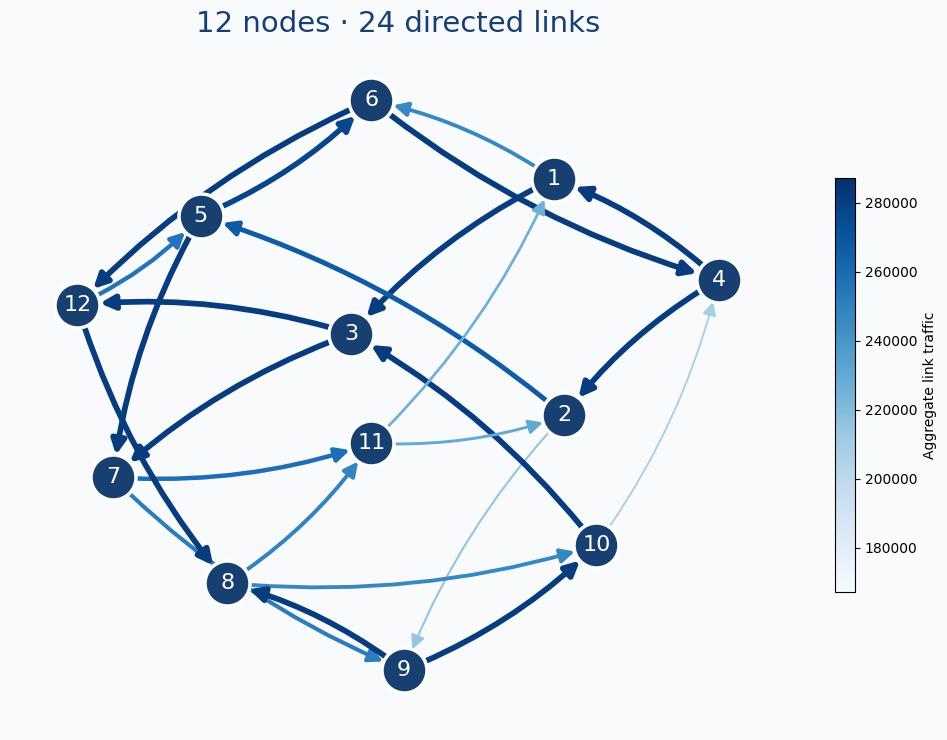

In [ ]:
#@title 12 · Draw the network computed in this run
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

network = nx.DiGraph()
network.add_nodes_from(range(N_NODES))
network.add_edges_from(best_result["arcs"])
loads = Counter({edge: 0 for edge in network.edges()})
for (source, tail, head), value in best_routing.flows.items():
    loads[tail, head] += value
positions = nx.kamada_kawai_layout(network.to_undirected())
values = [loads[edge] for edge in network.edges()]
normalization = Normalize(min(values), max(values))
figure, axes = plt.subplots(figsize=(10, 7.5), facecolor="#f8fafc")
axes.set_facecolor("#f8fafc")
nx.draw_networkx_edges(network, positions, ax=axes, arrows=True, arrowstyle="-|>",
    arrowsize=21, node_size=1050, connectionstyle="arc3,rad=0.10",
    edge_color=[plt.colormaps["Blues"](.35 + .6*normalization(v)) for v in values],
    width=[1.3 + 2.8*normalization(v) for v in values])
nx.draw_networkx_nodes(network, positions, ax=axes, node_size=1050,
    node_color="#173f70", edgecolors="white", linewidths=2.5)
nx.draw_networkx_labels(network, positions, ax=axes,
    labels={node:str(node+1) for node in network}, font_color="white", font_size=16)
axes.set_title("12 nodes · 24 directed links", fontsize=21, color="#173f70")
axes.axis("off")
figure.colorbar(ScalarMappable(norm=normalization, cmap="Blues"), ax=axes,
               shrink=.6, label="Aggregate link traffic")
figure.tight_layout()
plt.show()


In [ ]:
#@title 13 · Result from this execution
score = best_result["score"]
gap = 100 * (score / BENCHMARK - 1)
display(HTML(f"""<div style="background:#dbeafe;color:#102a43;border-left:7px solid #2563eb;
 border-radius:16px;padding:28px 32px;font-family:system-ui,sans-serif;">
 <div style="font-size:26px;font-weight:700;">network12 · Partitioned PCE</div>
 <div style="font-size:88px;font-weight:750;line-height:1.15;margin:12px 0 20px;">{score:,}</div>
 <div style="font-size:28px;">Benchmark: <b>{BENCHMARK:,}</b> · Gap: <b>{gap:.2f}%</b></div>
 </div>"""))
